<a href="https://colab.research.google.com/github/isabelacristina99/calculo_numerico_unifesp/blob/main/gauss_seidel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lista - Método de Gauss-Seidel

Sistema:

$10x - y + 2z = 6$

$-x + 11y - z = 22$

$2x - y + 10z = -10$

Primeiro conferi se a matriz é diagonal dominante, porque se for o método converge:

- linha 1: |10| > |-1| + |2| = 3
- linha 2: |11| > |-1| + |-1| = 2
- linha 3: |10| > |2| + |-1| = 3

Então é estritamente diagonal dominante e o Gauss-Seidel converge.

Isolando cada variável:

$x = (6 + y - 2z)/10$

$y = (22 + x + z)/11$

$z = (-10 - 2x + y)/10$

No Gauss-Seidel, quando calcula o x novo ele já é usado pra calcular o y, e o x e y novos já são usados no z (isso que diferencia do Jacobi).

Chute inicial: (0, 0, 0)

## Questão 5

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# chute inicial
x, y, z = 0, 0, 0

tol = 1e-5
k = 0

# listas pra guardar os valores de cada iteração (vou usar na tabela e nos gráficos)
lista_k = [0]
lista_x = [x]
lista_y = [y]
lista_z = [z]
lista_erro = [None]  # na iteração 0 não tem erro

erro = 1  # só pra entrar no while

while erro >= tol:
    k = k + 1

    # guarda os valores da iteração anterior
    x_ant, y_ant, z_ant = x, y, z

    # gauss-seidel: usa os valores novos assim que calcula
    x = (6 + y - 2*z) / 10
    y = (22 + x + z) / 11
    z = (-10 - 2*x + y) / 10

    # norma infinito = maior diferença em módulo
    erro = max(abs(x - x_ant), abs(y - y_ant), abs(z - z_ant))

    lista_k.append(k)
    lista_x.append(x)
    lista_y.append(y)
    lista_z.append(z)
    lista_erro.append(erro)

print("Número de iterações:", k)
print("x =", round(x, 6))
print("y =", round(y, 6))
print("z =", round(z, 6))

Número de iterações: 6
x = 1.0
y = 2.0
z = -1.0


Convergiu em 6 iterações e a solução aproximada é x = 1, y = 2, z = -1.

Testando no sistema:

$10(1) - 2 + 2(-1) = 6$

$-1 + 11(2) - (-1) = 22$

$2(1) - 2 + 10(-1) = -10$

Também comparei com o numpy pra ter certeza:

In [ ]:
A = np.array([[10, -1, 2], [-1, 11, -1], [2, -1, 10]])
b = np.array([6, 22, -10])
print(np.linalg.solve(A, b))

[ 1.  2. -1.]


Primeira iteração feita na mão pra conferir com o código:

$x^{(1)} = (6 + 0 - 0)/10 = 0,6$

$y^{(1)} = (22 + 0,6 + 0)/11 = 2,054545$

$z^{(1)} = (-10 - 1,2 + 2,054545)/10 = -0,914545$

erro = max(0,6; 2,054545; 0,914545) = 2,054545

Bateu com a linha k = 1 da tabela.

## Questão 6

In [ ]:
print(f"{'k':>2} | {'x(k)':>12} | {'y(k)':>12} | {'z(k)':>12} | {'erro':>12}")
print("-" * 63)
for i in range(len(lista_k)):
    if lista_erro[i] is None:
        e = "-"
    else:
        e = f"{lista_erro[i]:.4e}"
    print(f"{lista_k[i]:>2} | {lista_x[i]:>12.8f} | {lista_y[i]:>12.8f} | {lista_z[i]:>12.8f} | {e:>12}")

 k |         x(k) |         y(k) |         z(k) |         erro
---------------------------------------------------------------
 0 |   0.00000000 |   0.00000000 |   0.00000000 |            -
 1 |   0.60000000 |   2.05454545 |  -0.91454545 |   2.0545e+00
 2 |   0.98836364 |   2.00671074 |  -0.99700165 |   3.8836e-01
 3 |   1.00007140 |   2.00027907 |  -0.99998637 |   1.1708e-02
 4 |   1.00002518 |   2.00000353 |  -1.00000468 |   2.7554e-04
 5 |   1.00000129 |   1.99999969 |  -1.00000029 |   2.3892e-05
 6 |   1.00000003 |   1.99999998 |  -1.00000001 |   1.2626e-06


O erro diminui bastante a cada iteração. Em k = 5 ainda estava em 2,39e-05 (maior que a tolerância) e em k = 6 ficou 1,26e-06, por isso parou ali.

## Questão 7

a)

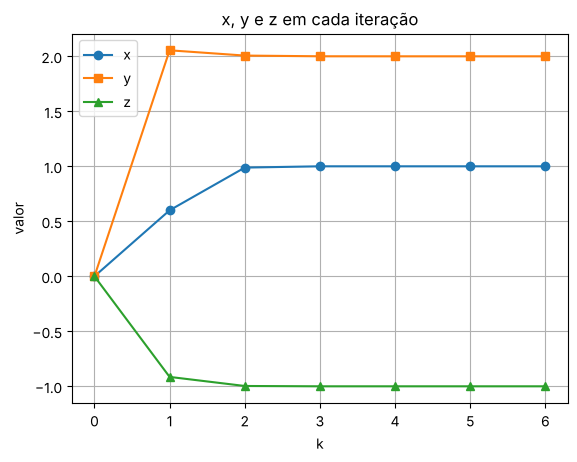

In [ ]:
plt.plot(lista_k, lista_x, 'o-', label='x')
plt.plot(lista_k, lista_y, 's-', label='y')
plt.plot(lista_k, lista_z, '^-', label='z')
plt.xlabel('k')
plt.ylabel('valor')
plt.title('x, y e z em cada iteração')
plt.legend()
plt.grid()
plt.show()

Os valores chegam perto de 1, 2 e -1 já na iteração 2 e depois quase não mudam mais.

b)

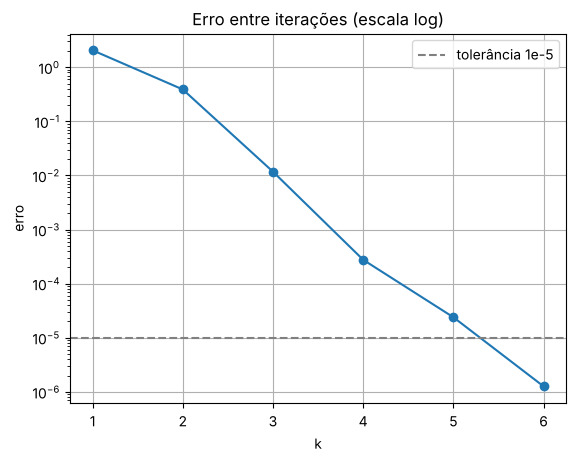

In [ ]:
# tirei o k = 0 porque não tem erro
plt.semilogy(lista_k[1:], lista_erro[1:], 'o-')
plt.axhline(tol, color='gray', linestyle='--', label='tolerância 1e-5')
plt.xlabel('k')
plt.ylabel('erro')
plt.title('Erro entre iterações (escala log)')
plt.legend()
plt.grid()
plt.show()

Na escala log o erro fica quase uma reta descendo, ou seja, ele vai sendo multiplicado mais ou menos pelo mesmo fator a cada iteração (convergência linear). Cada iteração ganha mais ou menos uma ou duas casas decimais de precisão. Converge rápido porque a diagonal da matriz é bem maior que os outros coeficientes.